# Comparing Methods with Simulated Data
Compare alternate methodology for estimating gene prevalence under the Bernoulli model.
These experiments all use simulated data that follows model assumptions (i.e. case in 
which model is well-specified).

For each approach, we calculate MSE on the full set of simulated genes, as well as subsets of the pangenome:
- Core (present in 100% of genomes)
- Flexible (missing in at least one genome)
- Extended core (present in >=90% genomes)
- Shell (present in between 15% and 90% of genomes)
- Cloud (present in <=15% of genomes)

These categorical definitions come from [Maistrenko et al. (2020)](https://doi.org/10.1038/s41396-020-0600-z) 
and [Dmitrijeva et al. (2024)](https://doi.org/10.1038/s41559-024-02357-0)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel
from gene_prevalence.simulations import build_observed_data_matrix, \
    build_presence_absence_matrix, build_three_part_pi_vector

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)

# set confidence interval alpha level
ci_alpha = 0.05


In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

### Generate simulated data
Generate ground truth simulated data

In [3]:
# build simulated data that matches model assumptions

n_genomes = 1000
n_genes = 12000

# # generate true pi values for all genes in the pangenome, with a three-part structure
# genes_per_genome = 3000
# n_core_genes = 800
# pi_vector_true = build_three_part_pi_vector(
#     pangenome_size=n_genes, 
#     genes_per_genome=genes_per_genome, 
#     n_core_genes=n_core_genes, 
#     non_core_span=(0.05, 1.0)
#     )

# generate true pi values for all genes in the pangenome, using a beta distribution
pi_vector_true = np.clip(rng.beta(a=0.2, b=0.5, size=n_genes) * 1.06, 0, 1)

# build a presence-absence matrix based on the true pi values
presence_absence_matrix = build_presence_absence_matrix(
    pi_vector=pi_vector_true, 
    n_genomes=n_genomes, 
    n_genes=n_genes,
    rng=rng
    )
print("Mean genes per genome:", round(presence_absence_matrix.sum(axis=1).mean()))

# generate completeness values for each genome, with a subset being complete
completeness_vector = pd.Series(
    np.clip(rng.uniform(low=0.05, high=1.1, size=n_genomes), 0, 1), 
    index=presence_absence_matrix.index
    )
print("N complete simulated genomes:", (completeness_vector == 1).sum())
print("N incomplete simulated genomes:", (completeness_vector < 1).sum())

# build an observed data matrix by simulating the observation process with no 
# gene-specific biases and not enforcing completeness (i.e. simulating each gene 
# observation as an independent Bernoulli trial)
observed_data_matrix, observation_mask = build_observed_data_matrix(
    presence_absence_matrix=presence_absence_matrix,
    completeness_levels=completeness_vector,
    rng=rng, 
    return_observation_mask=True
    )

observed_data_matrix


Mean genes per genome: 3534
N complete simulated genomes: 99
N incomplete simulated genomes: 901


,sim_gene_0,sim_gene_1,sim_gene_2,sim_gene_3,sim_gene_4,sim_gene_5,sim_gene_6,sim_gene_7,sim_gene_8,sim_gene_9,...,sim_gene_11990,sim_gene_11991,sim_gene_11992,sim_gene_11993,sim_gene_11994,sim_gene_11995,sim_gene_11996,sim_gene_11997,sim_gene_11998,sim_gene_11999
sim_genome_0,0,0,1,1,0,1,0,0,0,0,...,0,1,1,0,0,0,1,1,0,1
sim_genome_1,0,0,0,0,0,1,0,0,0,0,...,0,1,1,0,0,0,1,1,0,0
sim_genome_2,0,0,0,0,0,1,0,0,0,0,...,0,1,1,0,0,0,1,0,0,0
sim_genome_3,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
sim_genome_4,0,0,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sim_genome_995,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,1,1,0,1
sim_genome_996,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
sim_genome_997,0,0,0,0,0,1,0,0,0,0,...,0,1,1,0,0,0,0,1,0,0
sim_genome_998,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# subset all data to only observed genes for the method comparison

# identify observed genes
observed_genes = (observed_data_matrix.sum(axis=0) > 0)
observed_genes = observed_genes[observed_genes].index

# true pie values for observed genes
true_pi_values = pd.Series(pi_vector_true, index=presence_absence_matrix.columns)
true_pi_values = true_pi_values[observed_genes]

# observed data matrix for observed genes
observed_data_matrix = observed_data_matrix[observed_genes]

# assign genes to pangenome categories based on their true pi values
category_definitions = {
    'overall': true_pi_values.index, 
    'core': true_pi_values[true_pi_values == 1.0].index, 
    'extended_core': true_pi_values[true_pi_values >= 0.9].index,
    'flexible': true_pi_values[true_pi_values < 1.0].index,
    'shell': true_pi_values[(true_pi_values > 0.15) & (true_pi_values < 0.9)].index,
    'cloud': true_pi_values[true_pi_values <= 0.15].index
}

# print number of genes in each category
for category, genes in category_definitions.items():
    print(f"{category}: {len(genes)} genes")


overall: 9594 genes
core: 915 genes
extended_core: 1485 genes
flexible: 8679 genes
shell: 3908 genes
cloud: 4201 genes


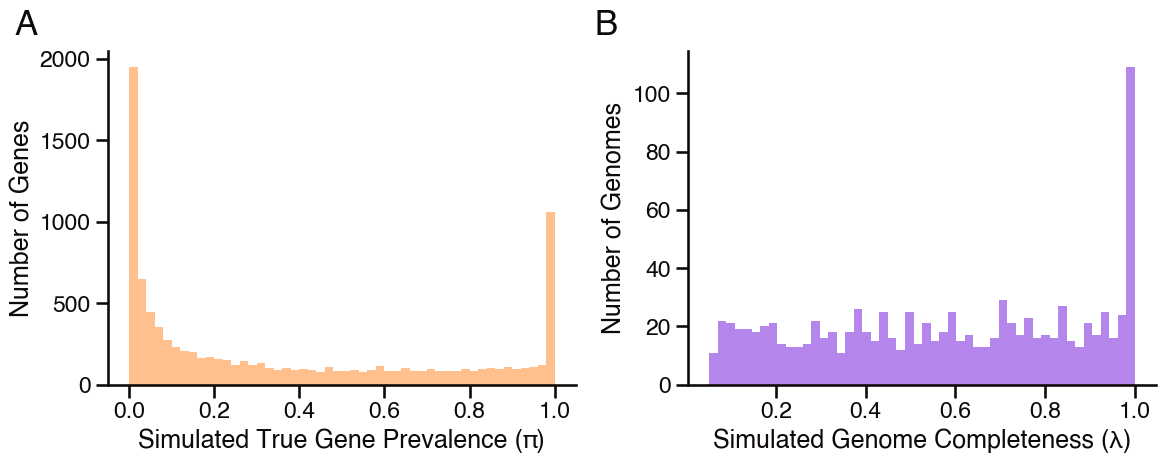

In [5]:
# plot distribution of true pi values and genome completeness values in simulated data

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(true_pi_values, bins=50, ax=axes[0], color=sns.color_palette()[1])
axes[0].set_xlabel("Simulated True Gene Prevalence (π)")
axes[0].set_ylabel("Number of Genes")
axes[0].annotate("A", xy=(-0.2, 1.05), xycoords='axes fraction', fontsize=25, fontweight='bold')
sns.histplot(completeness_vector, bins=50, ax=axes[1], color=sns.color_palette()[0])
axes[1].set_xlabel("Simulated Genome Completeness (λ)")
axes[1].set_ylabel("Number of Genomes")
axes[1].annotate("B", xy=(-0.2, 1.05), xycoords='axes fraction', fontsize=25, fontweight='bold')
plt.tight_layout()

### 1) Naive approach
Estimate gene prevalence as column means, without accounting for genome completeness

  method  gene_category  n_genes       mse
0  naive        overall     9594  0.048049
1  naive           core      915  0.177690
2  naive  extended_core     1485  0.172272
3  naive       flexible     8679  0.034381
4  naive          shell     3908  0.051838
5  naive          cloud     4201  0.000612


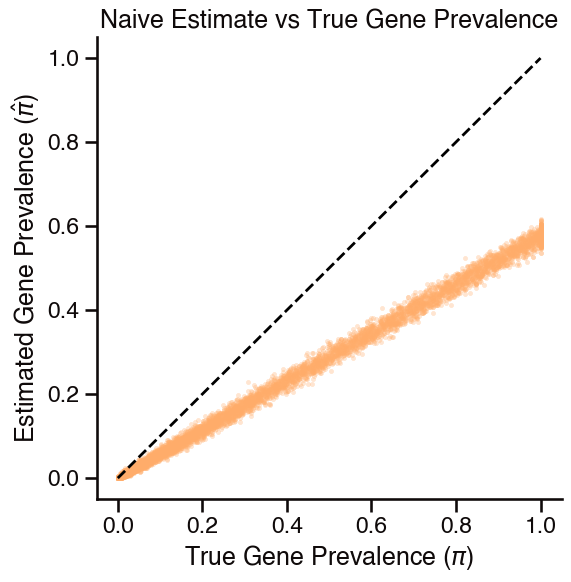

In [6]:
# estimate gene prevalence using naive approach (column means) and plot against true pi values

naive_pi_estimates = observed_data_matrix.mean(axis=0)

# calculate mse of naive estimates on full dataset and subset by gene category
results = []
for category, genes in category_definitions.items():
    mse = np.mean((naive_pi_estimates[genes] - true_pi_values[genes]) ** 2)
    results.append({
        'method': 'naive',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'naive'])

# build scatterplot of naive estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=true_pi_values, 
    y=naive_pi_estimates, 
    color=sns.color_palette()[1],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('Naive Estimate vs True Gene Prevalence')
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()


### 2) Subset approach
Estimate gene prevalence using only the complete genomes

    method  gene_category  n_genes       mse
6   subset        overall     9594  0.001004
7   subset           core      915  0.000000
8   subset  extended_core     1485  0.000150
9   subset       flexible     8679  0.001110
10  subset          shell     3908  0.002020
11  subset          cloud     4201  0.000361
There are 1046 genes not detected in any complete genome.


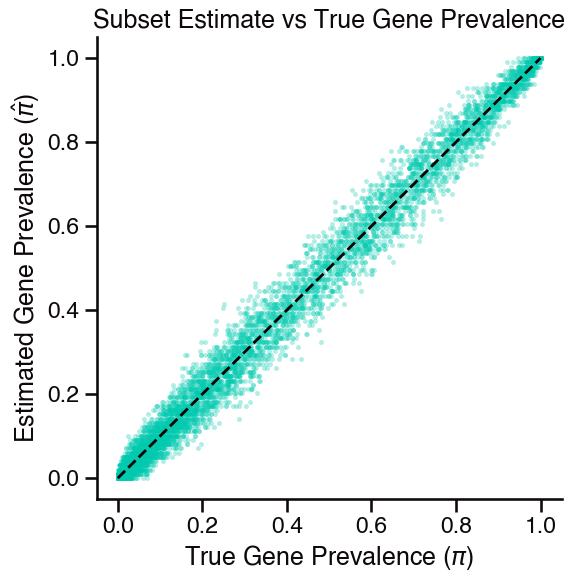

In [7]:
# estimate gene prevalence using subsetting approach (limit data to complete genomes) 
# and plot against true pi values

subset_pi_estimates = observed_data_matrix.loc[completeness_vector == 1].mean(axis=0)

# calculate mse of subset estimates on full dataset and subset by gene category
for category, genes in category_definitions.items():
    mse = np.mean((subset_pi_estimates[genes] - true_pi_values[genes]) ** 2)
    results.append({
        'method': 'subset',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'subset'])
print(f"There are {((subset_pi_estimates == 0).sum())} genes not detected in any complete genome.")

# build scatterplot of subset estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=true_pi_values, 
    y=subset_pi_estimates, 
    color=sns.color_palette()[2],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('Subset Estimate vs True Gene Prevalence')
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()

### 3) Unbiased estimator
Estimate gene prevalence using unbiased estimation, in combination with Chebychev method
for estimating confidence intervals. 

      method  gene_category  n_genes       mse
12  unbiased        overall     9594  0.000645
13  unbiased           core      915  0.000747
14  unbiased  extended_core     1485  0.001020
15  unbiased       flexible     8679  0.000634
16  unbiased          shell     3908  0.001077
17  unbiased          cloud     4201  0.000111


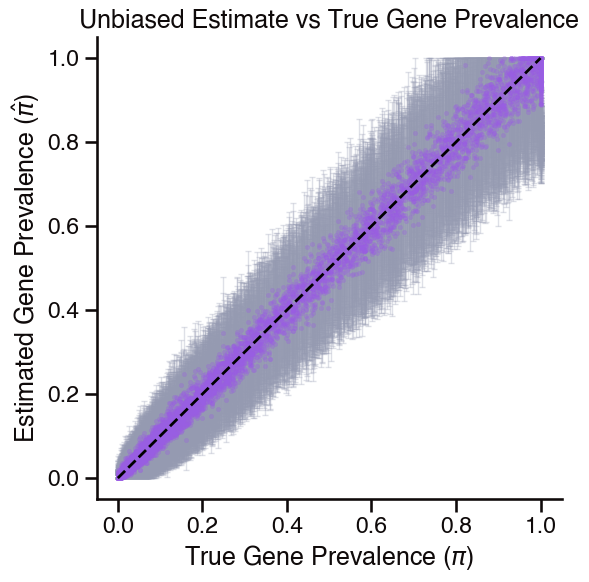

In [8]:
# estimate gene prevalence using unbiased estimator and plot against true pi values

# fit model to simulated dataset
model = BernoulliPrevalenceModel(
    data=observed_data_matrix,
    lambdas=completeness_vector,
)
fit = model.fit(
    estimator="unbiased",
    interval_method="chebyshev",
    alpha=ci_alpha,  # confidence interval alpha level
    clip=True,
)
pi_hat = fit.prevalence
ci_lower, ci_upper = fit.confidence_interval()  # confidence interval bounds

# pull results together into a dataframe
unbiased_estimates_df = pd.DataFrame(
    {
        "pi_true": true_pi_values,
        "pi_hat": pi_hat, 
        "ci_upper": ci_upper,
        "ci_lower": ci_lower,
    }
)

# calculate mse of unbiased estimates on full dataset and subset by gene category
for category, genes in category_definitions.items():
    mse = np.mean((unbiased_estimates_df.loc[genes, "pi_hat"] - unbiased_estimates_df.loc[genes, "pi_true"]) ** 2)
    results.append({
        'method': 'unbiased',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'unbiased'])

# build scatterplot of unbiased estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    color=sns.color_palette()[0],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('Unbiased Estimate vs True Gene Prevalence')
# add error bars for the configured confidence intervals
ax.errorbar(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    yerr=[unbiased_estimates_df["pi_hat"] - unbiased_estimates_df["ci_lower"], 
          unbiased_estimates_df["ci_upper"] - unbiased_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()


### 4) MLE estimator
Estimate gene prevalence using Maximum Likelihood Estimator, in combination with 
likelihood ratios for estimating confidence intervals.

   method  gene_category  n_genes       mse
18    mle        overall     9594  0.000215
19    mle           core      915  0.000003
20    mle  extended_core     1485  0.000084
21    mle       flexible     8679  0.000238
22    mle          shell     3908  0.000427
23    mle          cloud     4201  0.000065


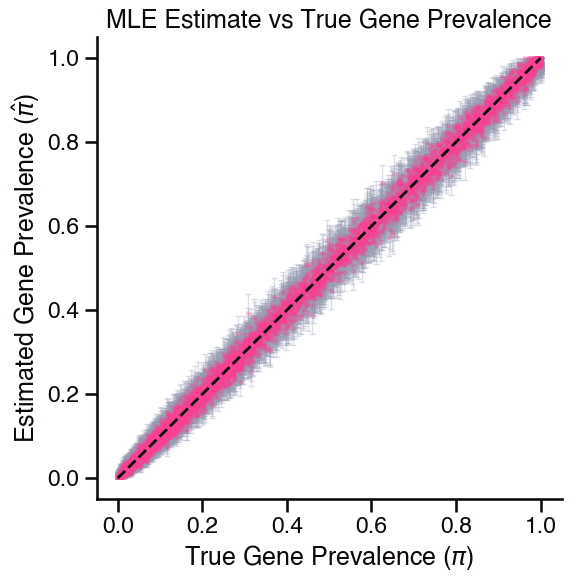

In [9]:
# estimate gene prevalence using MLE estimator and plot against true pi values

# fit model to simulated dataset
fit = model.fit(
    estimator="mle",
    interval_method="likelihood_ratio",
    alpha=ci_alpha,  # confidence interval alpha level
    clip=True,
)
pi_hat = fit.prevalence
ci_lower, ci_upper = fit.confidence_interval()  # confidence interval bounds

# pull results together into a dataframe
mle_estimates_df = pd.DataFrame(
    {
        "pi_true": true_pi_values,
        "pi_hat": pi_hat, 
        "ci_upper": ci_upper,
        "ci_lower": ci_lower,
    }
)

# calculate mse of MLE estimates on full dataset and subset by gene category
for category, genes in category_definitions.items():
    mse = np.mean((mle_estimates_df.loc[genes, "pi_hat"] - mle_estimates_df.loc[genes, "pi_true"]) ** 2)
    results.append({
        'method': 'mle',
        'gene_category': category,
        'n_genes': len(genes),
        'mse': mse
    })
mse_df = pd.DataFrame(results, columns=['method', 'gene_category', 'n_genes', 'mse'])
print(mse_df[mse_df['method'] == 'mle'])

# build scatterplot of MLE estimates vs true pi values
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    color=sns.color_palette()[3],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax
)
plt.xlabel(r"True Gene Prevalence ($\pi$)")
plt.ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
plt.title('MLE Estimate vs True Gene Prevalence')
# add error bars for the configured confidence intervals
ax.errorbar(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    yerr=[mle_estimates_df["pi_hat"] - mle_estimates_df["ci_lower"], 
          mle_estimates_df["ci_upper"] - mle_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax.plot(lims, lims, 'k--', zorder=1)
plt.show()


# Compound figure

Make summary figure that combines all experiments

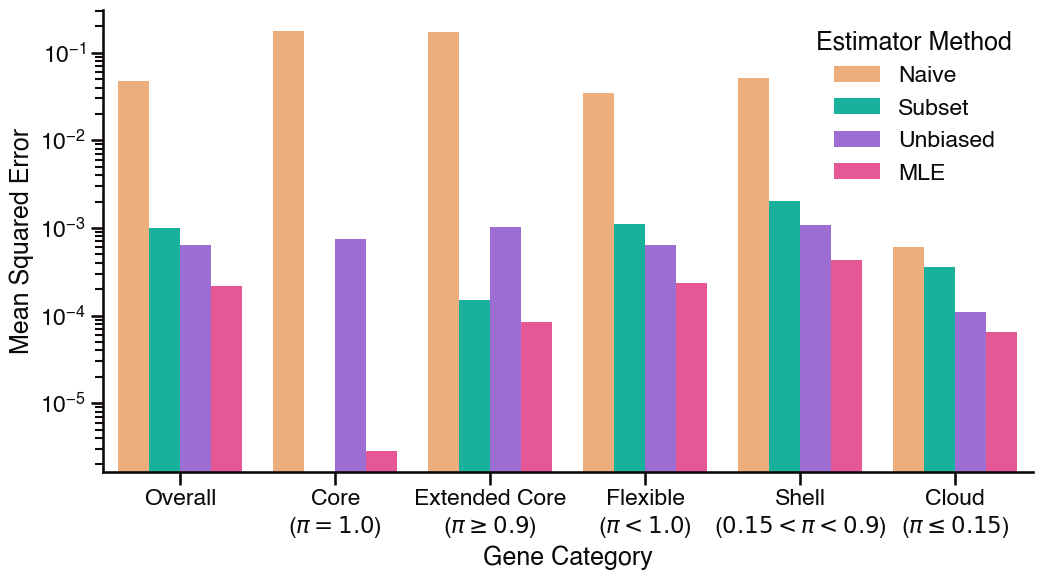

,method,gene_category,n_genes,mse,Gene Category,Estimator Method
0,naive,overall,9594,0.048049,Overall,Naive
1,naive,core,915,0.177690,Core\n($\pi=1.0$),Naive
2,naive,extended_core,1485,0.172272,Extended Core\n($\pi\geq0.9$),Naive
3,naive,flexible,8679,0.034381,Flexible\n($\pi<1.0$),Naive
4,naive,shell,3908,0.051838,Shell\n($0.15<\pi<0.9$),Naive
5,naive,cloud,4201,0.000612,Cloud\n($\pi\leq0.15$),Naive
6,subset,overall,9594,0.001004,Overall,Subset
7,subset,core,915,0.000000,Core\n($\pi=1.0$),Subset
8,subset,extended_core,1485,0.000150,Extended Core\n($\pi\geq0.9$),Subset
9,subset,flexible,8679,0.001110,Flexible\n($\pi<1.0$),Subset


In [10]:
# plot MSE results for all methods and gene categories

# add gene category labels for plotting
gene_category_labels = {
    'overall': 'Overall',
    'core': f"Core\n({r'$\pi=1.0$'})",
    'extended_core': f"Extended Core\n({r'$\pi\geq0.9$'})",
    'flexible': f"Flexible\n({r'$\pi<1.0$'})",
    'shell': f"Shell\n({r'$0.15<\pi<0.9$'})",
    'cloud': f"Cloud\n({r'$\pi\leq0.15$'})"
}
mse_df['Gene Category'] = mse_df['gene_category'].map(gene_category_labels)

# add estimator method labels for plotting
mse_df['Estimator Method'] = mse_df['method'].map({
    'naive': 'Naive',
    'subset': 'Subset',
    'unbiased': 'Unbiased',
    'mle': 'MLE'
})

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=mse_df, 
    x='Gene Category', 
    y='mse', 
    hue='Estimator Method', 
    ax=ax,
    palette=[sns.color_palette()[i] for i in [1, 2, 0, 3]]
)
ax.set_yscale('log')
ax.set_xlabel("Gene Category")
ax.set_ylabel("Mean Squared Error")
plt.show()

# show mse_df
mse_df

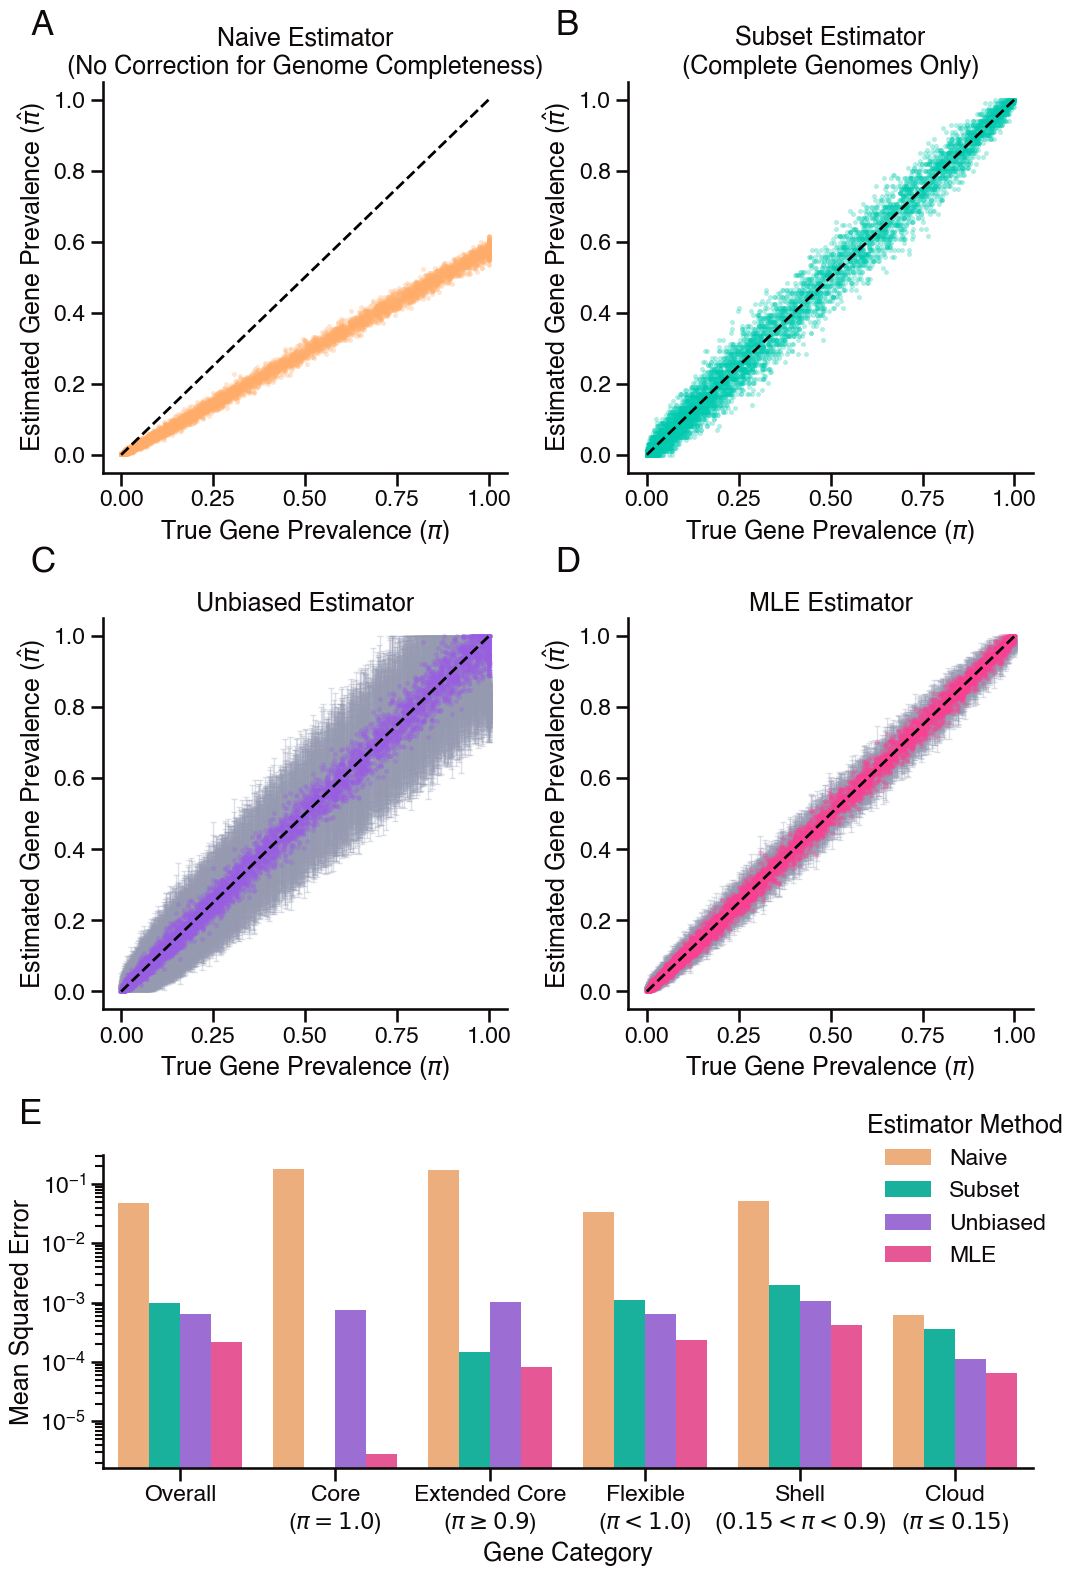

In [11]:
# combine all plots into a single publication-ready figure

# grid layout: 3 rows, 2 columns, bottom row for MSE barplot, top two rows for scatterplots of each method
fig = plt.figure(figsize=(12, 18))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.8], hspace=0.4, wspace=0.3)

# annotation specs
annotation_kwargs = dict(
    xy=(-0.18, 1.12),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# plot A: scatterplot of naive estimates vs true pi values
ax1 = fig.add_subplot(gs[0, 0])
sns.scatterplot(
    x=true_pi_values,
    y=naive_pi_estimates, 
    color=sns.color_palette()[1],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax1
)
ax1.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax1.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax1.set_title('Naive Estimator\n(No Correction for Genome Completeness)')
# add diagonal line for reference
lims = [0, 1]
ax1.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax1.annotate("A", **annotation_kwargs)

# plot B: scatterplot of subset estimates vs true pi values
ax2 = fig.add_subplot(gs[0, 1])
sns.scatterplot(
    x=true_pi_values,
    y=subset_pi_estimates, 
    color=sns.color_palette()[2],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax2
)
ax2.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax2.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax2.set_title('Subset Estimator\n(Complete Genomes Only)')
# add diagonal line for reference
lims = [0, 1]
ax2.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax2.annotate("B", **annotation_kwargs)

# plot C: scatterplot of unbiased estimates vs true pi values with error bars
ax3 = fig.add_subplot(gs[1, 0])
sns.scatterplot(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    color=sns.color_palette()[0],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax3
)
ax3.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax3.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax3.set_title('Unbiased Estimator')
# add error bars for the configured confidence intervals
ax3.errorbar(
    x=unbiased_estimates_df["pi_true"], 
    y=unbiased_estimates_df["pi_hat"], 
    yerr=[unbiased_estimates_df["pi_hat"] - unbiased_estimates_df["ci_lower"], 
          unbiased_estimates_df["ci_upper"] - unbiased_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax3.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax3.annotate("C", **annotation_kwargs)

# plot D: scatterplot of MLE estimates vs true pi values with error bars
ax4 = fig.add_subplot(gs[1, 1])
sns.scatterplot(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    color=sns.color_palette()[3],
    alpha=0.3,
    s=10,
    edgecolor=None,
    ax=ax4
)
ax4.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax4.set_ylabel(r"Estimated Gene Prevalence ($\hat{\pi}$)")
ax4.set_title('MLE Estimator')
# add error bars for the configured confidence intervals
ax4.errorbar(
    x=mle_estimates_df["pi_true"], 
    y=mle_estimates_df["pi_hat"], 
    yerr=[mle_estimates_df["pi_hat"] - mle_estimates_df["ci_lower"], 
          mle_estimates_df["ci_upper"] - mle_estimates_df["pi_hat"]],
    fmt='none',
    linewidth=1,
    capsize=2,
    ecolor=sns.color_palette()[5], 
    alpha=0.3,
    zorder=0
)
# add diagonal line for reference
lims = [0, 1]
ax4.plot(lims, lims, 'k--', zorder=1)
# add annotation
ax4.annotate("D", **annotation_kwargs)

# plot E: barplot of MSE results for all methods and gene categories
ax5 = fig.add_subplot(gs[2, :])
sns.barplot(
    data=mse_df, 
    x='Gene Category', 
    y='mse', 
    hue='Estimator Method', 
    ax=ax5,
    palette=[sns.color_palette()[i] for i in [1, 2, 0, 3]]
)
ax5.set_yscale('log')
ax5.set_ylabel("Mean Squared Error")
ax5.legend(title="Estimator Method", loc='upper left', bbox_to_anchor=(0.8, 1.2))
# add annotation
annotation_kwargs['xy'] = (-0.09, 1.1)
ax5.annotate("E", **annotation_kwargs)

# show and/or save figure
# fig.savefig("method_comparison_simulations_figure.png", bbox_inches='tight')
plt.show()


## Comparison of confidence intervals
Compare coverage and length of confidence intervals 

In [12]:
# calculate CIs at different alpha levels for unbiased and MLE estimators

# set different alpha levels to test
# alpha_values = np.array([0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
alpha_values = np.array([0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5])

# iterate through alpha values
ci_df = pd.DataFrame()
for a in alpha_values:
    for estimator in ['unbiased', 'mle']:
        interval_method = 'chebyshev' if estimator == 'unbiased' else 'likelihood_ratio'
        fit = model.fit(
            estimator=estimator,
            interval_method=interval_method,
            alpha=a,
            clip=True,
        )
        pi_hat = fit.prevalence
        ci_lower, ci_upper = fit.confidence_interval()
        coverage = np.mean((ci_lower <= true_pi_values) & (ci_upper >= true_pi_values))

        # append full data for plotting
        ci_df = pd.concat([ci_df, pd.DataFrame({
            'estimator': {'unbiased': 'Unbiased', 'mle': 'MLE'}[estimator],
            'interval_method': {'chebyshev': 'Chebyshev', 'likelihood_ratio': 'Likelihood Ratio'}[interval_method],
            'significance_level': a,
            'confidence_level': 1 - a,
            'pi_true': true_pi_values, 
            'pi_hat': pi_hat,
            'ci_lower': ci_lower,
            'ci_upper': ci_upper,
            'ci_width': ci_upper - ci_lower,
            'true_pi_in_ci': (ci_lower <= true_pi_values) & (ci_upper >= true_pi_values)
        })])

# show dataframe
ci_df = ci_df.reset_index().rename(columns={'index': 'gene'})
ci_df.head()

,gene,estimator,interval_method,significance_level,confidence_level,pi_true,pi_hat,ci_lower,ci_upper,ci_width,true_pi_in_ci
0,sim_gene_1,Unbiased,Chebyshev,0.01,0.99,0.001601,0.004916,0.000000,0.042347,0.042347,True
1,sim_gene_2,Unbiased,Chebyshev,0.01,0.99,0.211751,0.219857,0.000000,0.460551,0.460551,True
2,sim_gene_3,Unbiased,Chebyshev,0.01,0.99,0.661964,0.658451,0.278154,1.000000,0.721846,True
3,sim_gene_4,Unbiased,Chebyshev,0.01,0.99,0.001370,0.001124,0.000000,0.019032,0.019032,True
4,sim_gene_5,Unbiased,Chebyshev,0.01,0.99,0.969519,0.938444,0.514357,1.000000,0.485643,True


In [13]:
# calculate coverage and CI width for each estimator at the configured confidence level,
# grouped by gene category

# calculate mse of unbiased estimates on full dataset and subset by gene category
results = []
for category, genes in category_definitions.items():
    df = ci_df[ci_df.gene.isin(genes) & np.isclose(ci_df.confidence_level, 1 - ci_alpha)]
    for estimator in ['Unbiased', 'MLE']:
        estimator_df = df[df.estimator == estimator]
        coverage = np.mean(estimator_df['true_pi_in_ci'])
        mean_ci_width = estimator_df['ci_width'].mean()
        sd_ci_width = estimator_df['ci_width'].std()
        results.append({
            'method': estimator,
            'gene_category': category,
            'n_genes': len(genes),
            'coverage': coverage,
            'se_coverage': np.sqrt(coverage * (1 - coverage) / len(genes)),
            'mean_ci_width': mean_ci_width,
            'sd_ci_width': sd_ci_width
        })

# build dataframe
coverage_df = pd.DataFrame(results, columns=[
    'method', 'gene_category', 'n_genes', 'coverage', 'se_coverage', 'mean_ci_width', 'sd_ci_width'])
coverage_df['Gene Category'] = coverage_df['gene_category'].map(gene_category_labels)
coverage_df

,method,gene_category,n_genes,coverage,se_coverage,mean_ci_width,sd_ci_width,Gene Category
0,Unbiased,overall,9594,0.999583,0.000208,0.180269,0.111534,Overall
1,MLE,overall,9594,0.956014,0.002094,0.049957,0.029953,Overall
2,Unbiased,core,915,1.000000,0.000000,0.188167,0.041500,Core\n($\pi=1.0$)
3,MLE,core,915,1.000000,0.000000,0.016510,0.006800,Core\n($\pi=1.0$)
4,Unbiased,extended_core,1485,1.000000,0.000000,0.207387,0.050771,Extended Core\n($\pi\geq0.9$)
5,MLE,extended_core,1485,0.973737,0.004150,0.030237,0.021040,Extended Core\n($\pi\geq0.9$)
6,Unbiased,flexible,8679,0.999539,0.000230,0.179437,0.116460,Flexible\n($\pi<1.0$)
7,MLE,flexible,8679,0.951377,0.002309,0.053483,0.029266,Flexible\n($\pi<1.0$)
8,Unbiased,shell,3908,1.000000,0.000000,0.284512,0.055640,Shell\n($0.15<\pi<0.9$)
9,MLE,shell,3908,0.950358,0.003474,0.081402,0.009579,Shell\n($0.15<\pi<0.9$)


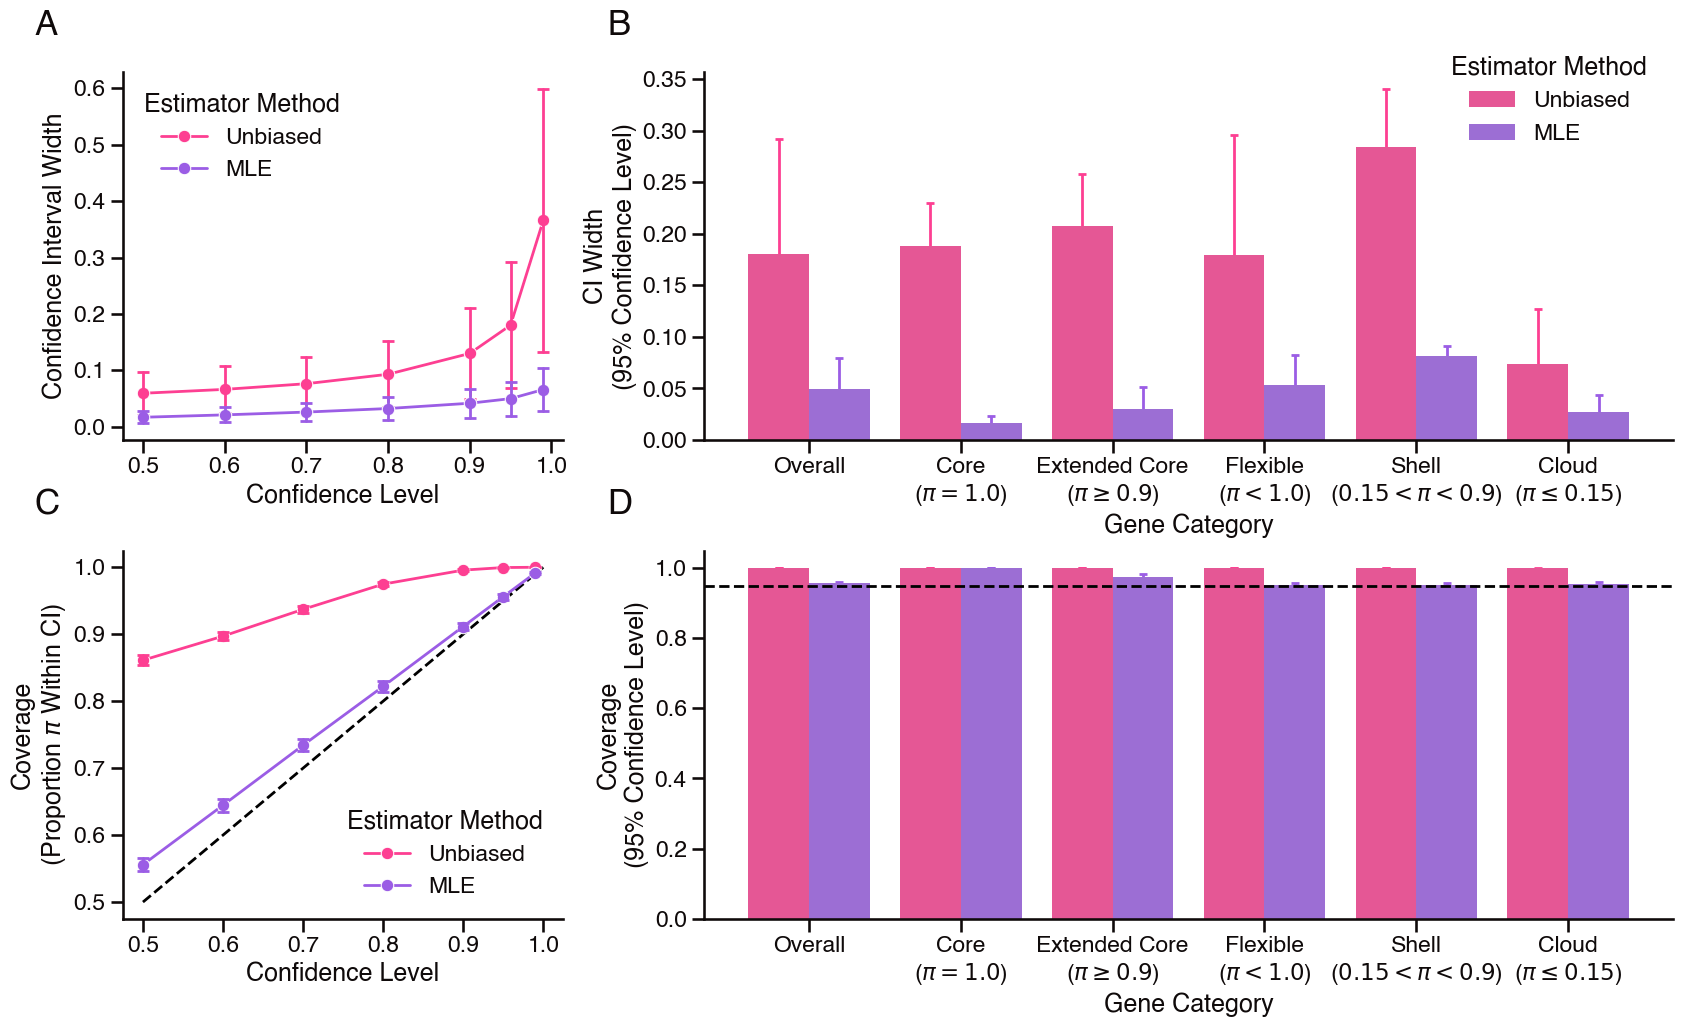

In [14]:
# build compound figure comparing confidence intervals between methods

# annotation specs
annotation_kwargs = dict(
    xy=(-0.2, 1.1),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# order of genes and hues
gene_category_order = coverage_df['Gene Category'].unique()
estimator_order = ['Unbiased', 'MLE']

# build compound figure with 2 rows and 2 columns
fig = plt.figure(figsize=(20, 11))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.2], hspace=0.3, wspace=0.2)

# plot A: lineplot of CI width vs confidence level for each estimator method
ax1 = fig.add_subplot(gs[0, 0])
sns.lineplot(
    data=ci_df, 
    x='confidence_level', 
    y='ci_width', 
    hue='estimator', 
    hue_order=estimator_order,
    estimator='mean',
    errorbar='sd',
    err_style='bars',
    err_kws={'capsize': 4, 'elinewidth': 2, 'capthick': 2},
    marker='o',
    ax=ax1,
    palette=[sns.color_palette()[i] for i in [3, 0]]
)
ax1.set_xlabel("Confidence Level")
ax1.set_ylabel("Confidence Interval Width")
ax1.legend(title="Estimator Method")
# add annotation
ax1.annotate("A", **annotation_kwargs)

# plot B: barplot of mean CI width at the configured confidence level grouped by gene category for each estimator method
ax2 = fig.add_subplot(gs[0, 1])
sns.barplot(
    data=coverage_df, 
    x='Gene Category', 
    order=gene_category_order,
    y='mean_ci_width', 
    hue='method', 
    hue_order=estimator_order,
    ax=ax2,
    palette=[sns.color_palette()[i] for i in [3, 0]]
)
# add error bars at the centers of the bars
for container, method in zip(ax2.containers, estimator_order):
    for patch, gene_category in zip(container.patches, gene_category_order):
        x = patch.get_x() + patch.get_width() / 2
        y = patch.get_height()
        err = coverage_df.set_index(['Gene Category', 'method']).loc[(gene_category, method), 'sd_ci_width']
        ax2.errorbar(
            x=x,
            y=y,
            yerr=err,
            fmt="none",
            c={'Unbiased': sns.color_palette()[3], 'MLE': sns.color_palette()[0]}[method],
            capsize=3,
            elinewidth=2,
            capthick=2,
            zorder=0
        )
ax2.set_ylabel(f"CI Width\n({(1 - ci_alpha):.0%} Confidence Level)")
ax2.legend(title="Estimator Method", loc='upper left', bbox_to_anchor=(0.75, 1.1))
# add annotation
annotation_kwargs['xy'] = (-0.1, 1.1)
ax2.annotate("B", **annotation_kwargs)

# plot C: lineplot of coverage vs confidence level for each estimator method
ax3 = fig.add_subplot(gs[1, 0])
sns.lineplot(
    data=ci_df, 
    x='confidence_level', 
    y='true_pi_in_ci', 
    hue='estimator', 
    hue_order=estimator_order,
    estimator='mean',
    errorbar=('se', 2),
    err_style='bars',
    err_kws={'capsize': 4, 'elinewidth': 2, 'capthick': 2},
    marker='o',
    ax=ax3,
    palette=[sns.color_palette()[i] for i in [3, 0]]
)
ax3.set_xlabel("Confidence Level")
ax3.set_ylabel(f"Coverage\n(Proportion {r'$\pi$'} Within CI)")
ax3.legend(title="Estimator Method")
# add 1:1 line for reference
ax3.plot([0.5, 1], [0.5, 1], 'k--', zorder=1)
# add annotation
annotation_kwargs['xy'] = (-0.2, 1.1)
ax3.annotate("C", **annotation_kwargs)

# plot D: barplot of coverage at the configured confidence level grouped by gene category for each estimator method
ax4 = fig.add_subplot(gs[1, 1])
sns.barplot(
    data=coverage_df, 
    x='Gene Category',
    order=gene_category_order, 
    y='coverage', 
    hue='method', 
    hue_order=estimator_order,
    ax=ax4,
    palette=[sns.color_palette()[i] for i in [3, 0]], 
    legend=False
)
# add error bars at +/- 2 standard errors of the coverage proportion
for container, method in zip(ax4.containers, estimator_order):
    for patch, gene_category in zip(container.patches, gene_category_order):
        x = patch.get_x() + patch.get_width() / 2
        y = patch.get_height()
        err = 2 * coverage_df.set_index(['Gene Category', 'method']).loc[(gene_category, method), 'se_coverage']
        ax4.errorbar(
            x=x,
            y=y,
            yerr=err,
            fmt="none",
            c={'Unbiased': sns.color_palette()[3], 'MLE': sns.color_palette()[0]}[method],
            capsize=3,
            elinewidth=2,
            capthick=2,
            zorder=0
        )
ax4.set_ylabel(f"Coverage\n({(1 - ci_alpha):.0%} Confidence Level)")
# add horizontal line for reference at the nominal coverage level
ax4.axhline(1 - ci_alpha, color='k', linestyle='--', zorder=1)
# add annotation
annotation_kwargs['xy'] = (-0.1, 1.1)
ax4.annotate("D", **annotation_kwargs)

# show and/or save figure
# fig.savefig("ci_comparison_figure.png", bbox_inches='tight')
plt.show()